In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import shutil, os
source = '/content/drive/MyDrive/curcuminoid_cyclodextrin_project/bcd_cur_100ns_Final_Result_PBC'
dest = '/content/bcd_cur_100ns_Final_Result_PBC'

if os.path.exists(dest):
    shutil.rmtree(dest)
shutil.copytree(source, dest)
print("Copied:", os.listdir(dest))

Mounted at /content/drive
Copied: ['.step5_production.xtc_offsets.npz', 'step5_production_fixed.xtc', 'step5_production.log', 'step5_production.xtc', '#step5_production_fixed2.xtc.1#', 'step5_production.tpr', 'step5_production_fixed2.xtc', 'index.ndx', 'step5_production.edr', 'step5_production.gro']


In [ ]:
!pip install -q MDAnalysis matplotlib numpy scipy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.9/108.9 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 84.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 91.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 4.4 MB/s eta 0:00:00


In [ ]:
%cd /content/bcd_cur_100ns_Final_Result_PBC

import MDAnalysis as mda
import numpy as np
import matplotlib.pyplot as plt

u = mda.Universe("step5_production.tpr", "step5_production_fixed2.xtc")
print(f"Loaded {len(u.trajectory)} frames")
print(f"Atoms: {len(u.atoms)}")

/content/bcd_cur_100ns_Final_Result_PBC


Loaded 1001 frames
Atoms: 4298


In [ ]:
from MDAnalysis.analysis import align
align.AlignTraj(u, u, select='all', in_memory=True).run()
print("Aligned to frame 0")

Aligned to frame 0


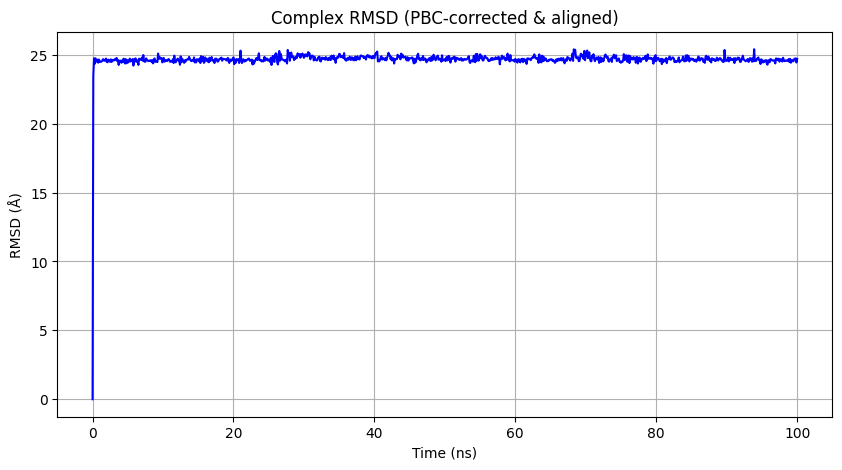

Avg RMSD: 24.67 Å


In [ ]:
from MDAnalysis.analysis import rms

rmsd_complex = rms.RMSD(u, u, select='all', ref_frame=0).run()

plt.figure(figsize=(10, 5))
plt.plot(rmsd_complex.results.rmsd[:, 1] / 1000,
         rmsd_complex.results.rmsd[:, 2], color='blue')
plt.xlabel('Time (ns)')
plt.ylabel('RMSD (Å)')
plt.title('Complex RMSD (PBC-corrected & aligned)')
plt.grid(True)
plt.savefig('rmsd_complex.png', dpi=150)
plt.show()

print(f"Avg RMSD: {rmsd_complex.results.rmsd[:, 2].mean():.2f} Å")

In [ ]:
u = mda.Universe("step5_production.tpr", "step5_production_fixed2.xtc")
print("Frames:", len(u.trajectory))
print("Atoms:", len(u.atoms))
print("Box dimensions:", u.dimensions)
print("First 5 residue names:", [r.resname for r in u.residues[:5]])
print("Unique resnames:", set(r.resname for r in u.residues))

Frames: 1001
Atoms: 4298
Box dimensions: [36. 36. 36. 90. 90. 90.]
First 5 residue names: ['CUR', 'BCD', 'SOD', 'SOD', 'SOD']
Unique resnames: {'SOD', 'CLA', 'CUR', 'TIP3', 'BCD'}


In [ ]:
u.trajectory[0]
pos_0 = u.atoms.positions.copy()

u.trajectory[500]
pos_500 = u.atoms.positions.copy()

diff = np.linalg.norm(pos_500 - pos_0, axis=1)
print(f"Max displacement: {diff.max():.2f} Å")
print(f"Mean displacement: {diff.mean():.2f} Å")
print(f"Atoms displaced > 10 Å: {(diff > 10).sum()}")
print(f"Atoms displaced > 20 Å: {(diff > 20).sum()}")

# Split by residue
for resname in ['BCD', 'CUR', 'TIP3', 'SOD', 'CLA']:
    sel = u.select_atoms(f"resname {resname}")
    idx = sel.indices
    d = diff[idx]
    print(f"\n{resname}: mean {d.mean():.2f} Å, max {d.max():.2f} Å, "
          f"atoms >10 Å: {(d > 10).sum()}")

Max displacement: 52.97 Å
Mean displacement: 23.19 Å
Atoms displaced > 10 Å: 4001
Atoms displaced > 20 Å: 2684

BCD: mean 17.33 Å, max 25.46 Å, atoms >10 Å: 147

CUR: mean 16.28 Å, max 21.75 Å, atoms >10 Å: 44

TIP3: mean 23.48 Å, max 52.97 Å, atoms >10 Å: 3805

SOD: mean 19.48 Å, max 27.47 Å, atoms >10 Å: 2

CLA: mean 28.56 Å, max 38.70 Å, atoms >10 Å: 3


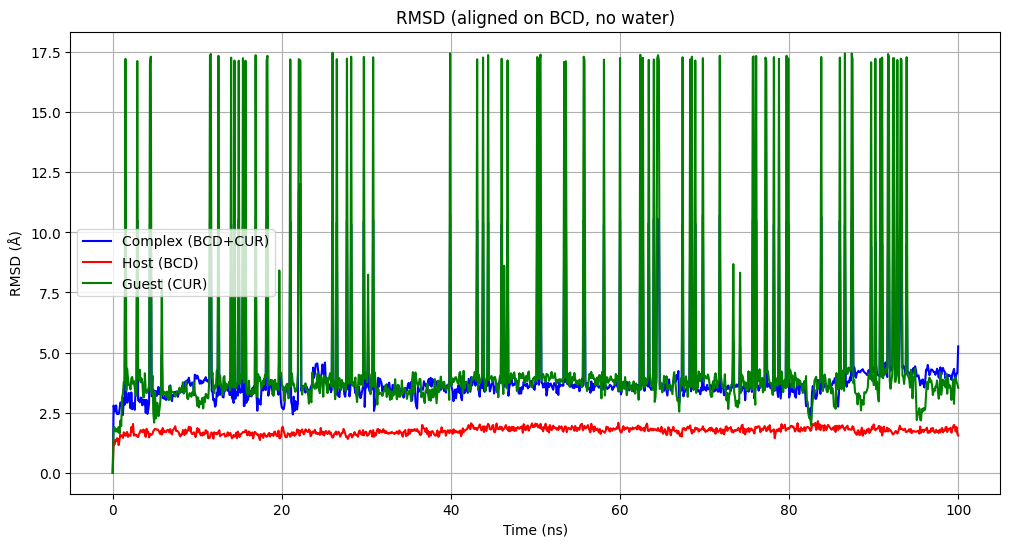

Complex RMSD: 4.12 ± 1.90 Å
Host RMSD:    1.74 ± 0.15 Å
Guest RMSD:   4.72 ± 3.74 Å


In [ ]:
from MDAnalysis.analysis import align, rms

# Align only on the host (BCD) — this is the correct reference
align.AlignTraj(u, u, select='resname BCD', in_memory=True).run()

# Now calculate RMSD on BCD only (reference = frame 0, aligned)
rmsd_host = rms.RMSD(u, u, select='resname BCD', ref_frame=0).run()
# RMSD on CUR only
rmsd_guest = rms.RMSD(u, u, select='resname CUR', ref_frame=0).run()
# RMSD on BCD+CUR together
rmsd_complex = rms.RMSD(u, u, select='resname BCD or resname CUR', ref_frame=0).run()

plt.figure(figsize=(12, 6))
plt.plot(rmsd_complex.results.rmsd[:, 1]/1000,
         rmsd_complex.results.rmsd[:, 2], label='Complex (BCD+CUR)', color='blue')
plt.plot(rmsd_host.results.rmsd[:, 1]/1000,
         rmsd_host.results.rmsd[:, 2], label='Host (BCD)', color='red')
plt.plot(rmsd_guest.results.rmsd[:, 1]/1000,
         rmsd_guest.results.rmsd[:, 2], label='Guest (CUR)', color='green')
plt.xlabel('Time (ns)')
plt.ylabel('RMSD (Å)')
plt.title('RMSD (aligned on BCD, no water)')
plt.legend()
plt.grid(True)
plt.savefig('rmsd_overlay_correct.png', dpi=150)
plt.show()

print(f"Complex RMSD: {rmsd_complex.results.rmsd[:, 2].mean():.2f} ± {rmsd_complex.results.rmsd[:, 2].std():.2f} Å")
print(f"Host RMSD:    {rmsd_host.results.rmsd[:, 2].mean():.2f} ± {rmsd_host.results.rmsd[:, 2].std():.2f} Å")
print(f"Guest RMSD:   {rmsd_guest.results.rmsd[:, 2].mean():.2f} ± {rmsd_guest.results.rmsd[:, 2].std():.2f} Å")

In [ ]:
# Track CUR COM distance from BCD COM, frame by frame
host_com = u.select_atoms("resname BCD").center_of_mass()
guest = u.select_atoms("resname CUR")

distances = []
for ts in u.trajectory:
    d = np.linalg.norm(host.center_of_mass() - guest.center_of_mass())
    distances.append(d)
distances = np.array(distances)

# How many frames have distance > 12 Å?
far_frames = np.where(distances > 12)[0]
print(f"Frames with CUR > 12 Å from BCD: {len(far_frames)}")
print(f"Frame indices: {far_frames[:20]}...")  # first 20

# Are they isolated single-frame events or consecutive?
if len(far_frames) > 1:
    gaps = np.diff(far_frames)
    print(f"\nGap between spikes (frames): {gaps[:20]}")
    print(f"Consecutive frames (gap=1): {(gaps == 1).sum()}")
    print(f"Isolated frames (gap>1): {(gaps > 1).sum()}")

NameError: name 'host' is not defined

In [ ]:
host = u.select_atoms("resname BCD")
guest = u.select_atoms("resname CUR")

distances = []
for ts in u.trajectory:
    d = np.linalg.norm(host.center_of_mass() - guest.center_of_mass())
    distances.append(d)
distances = np.array(distances)

# How many frames have distance > 12 Å?
far_frames = np.where(distances > 12)[0]
print(f"Total frames: {len(distances)}")
print(f"Frames with CUR > 12 Å from BCD: {len(far_frames)}")
print(f"Percentage: {100*len(far_frames)/len(distances):.1f}%")

# Are the spikes isolated or consecutive?
if len(far_frames) > 1:
    gaps = np.diff(far_frames)
    print(f"\nFirst 30 spike frame indices: {far_frames[:30]}")
    print(f"First 30 gaps between spikes: {gaps[:30]}")
    print(f"\nGap = 1 (consecutive): {(gaps == 1).sum()}")
    print(f"Gap = 2 (1 frame between): {(gaps == 2).sum()}")
    print(f"Gap > 5 (isolated): {(gaps > 5).sum()}")

# Distribution of the distance
print(f"\nDistance stats:")
print(f"  Min:    {distances.min():.2f} Å")
print(f"  Median: {np.median(distances):.2f} Å")
print(f"  Mean:   {distances.mean():.2f} Å")
print(f"  Max:    {distances.max():.2f} Å")
print(f"  95th percentile: {np.percentile(distances, 95):.2f} Å")

Total frames: 1001
Frames with CUR > 12 Å from BCD: 4
Percentage: 0.4%

First 30 spike frame indices: [ 15 220 221 222]
First 30 gaps between spikes: [205   1   1]

Gap = 1 (consecutive): 2
Gap = 2 (1 frame between): 0
Gap > 5 (isolated): 1

Distance stats:
  Min:    0.18 Å
  Median: 2.01 Å
  Mean:   2.33 Å
  Max:    28.83 Å
  95th percentile: 4.33 Å


In [ ]:
# Reload fresh to be safe
u = mda.Universe("step5_production.tpr", "step5_production_fixed2.xtc")

# Unwrap so no molecule appears to jump across the box boundary
u.atoms.unwrap(compound='fragments')
print("Trajectory unwrapped")

Trajectory unwrapped


In [ ]:
from MDAnalysis.analysis import align
align.AlignTraj(u, u, select='resname BCD', in_memory=True).run()
print("Aligned on BCD")

Aligned on BCD


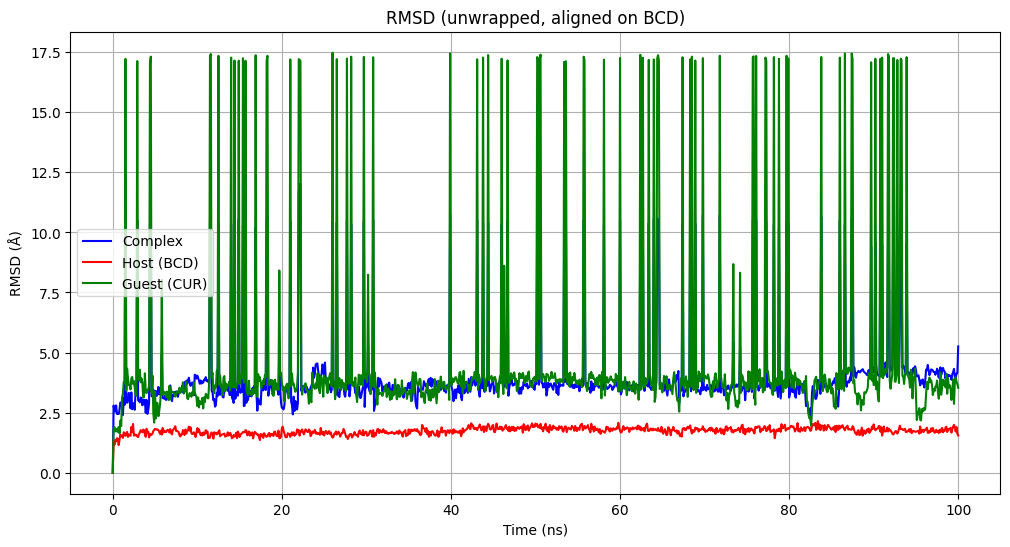

Complex RMSD: 4.12 ± 1.90 Å
Host RMSD:    1.74 ± 0.15 Å
Guest RMSD:   4.72 ± 3.74 Å


In [ ]:
from MDAnalysis.analysis import rms

rmsd_complex = rms.RMSD(u, u, select='resname BCD or resname CUR', ref_frame=0).run()
rmsd_host = rms.RMSD(u, u, select='resname BCD', ref_frame=0).run()
rmsd_guest = rms.RMSD(u, u, select='resname CUR', ref_frame=0).run()

plt.figure(figsize=(12, 6))
plt.plot(rmsd_complex.results.rmsd[:, 1]/1000,
         rmsd_complex.results.rmsd[:, 2], label='Complex', color='blue')
plt.plot(rmsd_host.results.rmsd[:, 1]/1000,
         rmsd_host.results.rmsd[:, 2], label='Host (BCD)', color='red')
plt.plot(rmsd_guest.results.rmsd[:, 1]/1000,
         rmsd_guest.results.rmsd[:, 2], label='Guest (CUR)', color='green')
plt.xlabel('Time (ns)')
plt.ylabel('RMSD (Å)')
plt.title('RMSD (unwrapped, aligned on BCD)')
plt.legend()
plt.grid(True)
plt.savefig('rmsd_final.png', dpi=150)
plt.show()

print(f"Complex RMSD: {rmsd_complex.results.rmsd[:, 2].mean():.2f} ± {rmsd_complex.results.rmsd[:, 2].std():.2f} Å")
print(f"Host RMSD:    {rmsd_host.results.rmsd[:, 2].mean():.2f} ± {rmsd_host.results.rmsd[:, 2].std():.2f} Å")
print(f"Guest RMSD:   {rmsd_guest.results.rmsd[:, 2].mean():.2f} ± {rmsd_guest.results.rmsd[:, 2].std():.2f} Å")

In [ ]:
# Compute median RMSD (robust to outliers)
print(f"Complex RMSD (median): {np.median(rmsd_complex.results.rmsd[:, 2]):.2f} Å")
print(f"Host RMSD (median):    {np.median(rmsd_host.results.rmsd[:, 2]):.2f} Å")
print(f"Guest RMSD (median):   {np.median(rmsd_guest.results.rmsd[:, 2]):.2f} Å")

Complex RMSD (median): 3.61 Å
Host RMSD (median):    1.75 Å
Guest RMSD (median):   3.70 Å


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import shutil, os
source = '/content/drive/MyDrive/curcuminoid_cyclodextrin_project/bcd_cur_100ns_Final_Result_PBC'
dest = '/content/bcd_cur_100ns_Final_Result_PBC'

if os.path.exists(dest):
    shutil.rmtree(dest)
shutil.copytree(source, dest)
print("Files:", os.listdir(dest))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files: ['.step5_production.xtc_offsets.npz', 'step5_production_fixed.xtc', 'step5_production.log', 'step5_production.xtc', 'step5_production_nojump.xtc', '#step5_production_fixed2.xtc.1#', 'step5_production.tpr', 'step5_production_fixed2.xtc', 'index.ndx', 'step5_production.edr', 'step5_production.gro']


/content/bcd_cur_100ns_Final_Result_PBC
Loaded 1001 frames


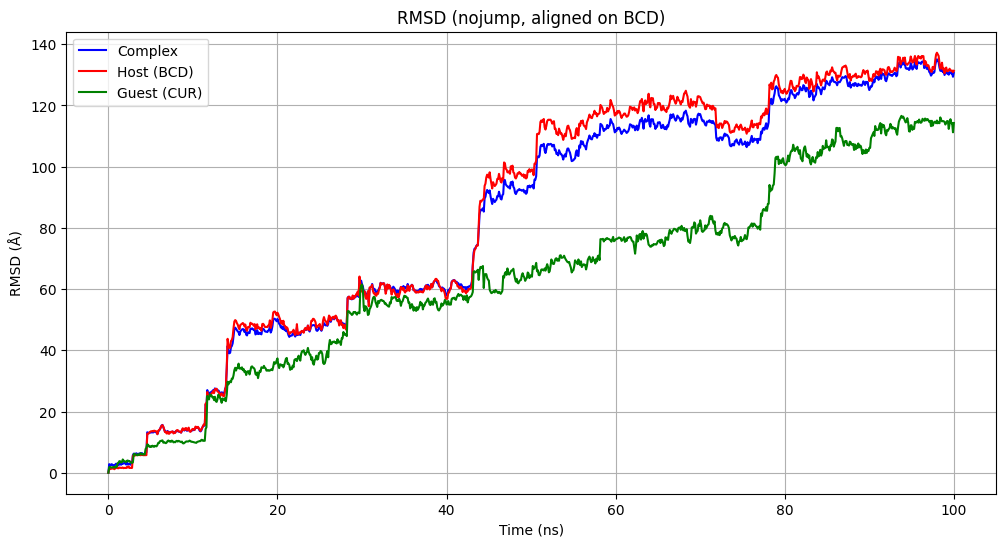

Complex RMSD: 82.65 ± 40.41 Å
Host RMSD:    85.18 ± 42.21 Å
Guest RMSD:   64.22 ± 31.93 Å


In [ ]:
%cd /content/bcd_cur_100ns_Final_Result_PBC

import MDAnalysis as mda
import numpy as np
import matplotlib.pyplot as plt
from MDAnalysis.analysis import align, rms

# Load the NOJUMP trajectory (this is the key change)
u = mda.Universe("step5_production.tpr", "step5_production_nojump.xtc")
print(f"Loaded {len(u.trajectory)} frames")

# Align on BCD
align.AlignTraj(u, u, select='resname BCD', in_memory=True).run()

# Calculate RMSD for the three cases
rmsd_complex = rms.RMSD(u, u, select='resname BCD or resname CUR', ref_frame=0).run()
rmsd_host = rms.RMSD(u, u, select='resname BCD', ref_frame=0).run()
rmsd_guest = rms.RMSD(u, u, select='resname CUR', ref_frame=0).run()

plt.figure(figsize=(12, 6))
plt.plot(rmsd_complex.results.rmsd[:, 1]/1000,
         rmsd_complex.results.rmsd[:, 2], label='Complex', color='blue')
plt.plot(rmsd_host.results.rmsd[:, 1]/1000,
         rmsd_host.results.rmsd[:, 2], label='Host (BCD)', color='red')
plt.plot(rmsd_guest.results.rmsd[:, 1]/1000,
         rmsd_guest.results.rmsd[:, 2], label='Guest (CUR)', color='green')
plt.xlabel('Time (ns)')
plt.ylabel('RMSD (Å)')
plt.title('RMSD (nojump, aligned on BCD)')
plt.legend()
plt.grid(True)
plt.savefig('rmsd_final.png', dpi=150)
plt.show()

print(f"Complex RMSD: {rmsd_complex.results.rmsd[:, 2].mean():.2f} ± {rmsd_complex.results.rmsd[:, 2].std():.2f} Å")
print(f"Host RMSD:    {rmsd_host.results.rmsd[:, 2].mean():.2f} ± {rmsd_host.results.rmsd[:, 2].std():.2f} Å")
print(f"Guest RMSD:   {rmsd_guest.results.rmsd[:, 2].mean():.2f} ± {rmsd_guest.results.rmsd[:, 2].std():.2f} Å")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import shutil, os
source = '/content/drive/MyDrive/curcuminoid_cyclodextrin_project/bcd_cur_100ns_Final_Result_PBC'
dest = '/content/bcd_cur_100ns_Final_Result_PBC'

if os.path.exists(dest):
    shutil.rmtree(dest)
shutil.copytree(source, dest)
print("Files:", os.listdir(dest))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files: ['.step5_production.xtc_offsets.npz', 'step5_production_fixed.xtc', 'step5_production_nojump2.xtc', 'step5_production.log', 'step5_production.xtc', 'step5_production_nojump.xtc', '#step5_production_fixed2.xtc.1#', 'step5_production.tpr', 'step5_production_fixed2.xtc', 'index.ndx', 'step5_production.edr', 'step5_production.gro']


In [ ]:
%cd /content/bcd_cur_100ns_Final_Result_PBC

import MDAnalysis as mda
import numpy as np

u_test = mda.Universe("step5_production.tpr", "step5_production_nojump2.xtc")
print(f"Frames: {len(u_test.trajectory)}")
print(f"Atoms: {len(u_test.atoms)}")

u_test.trajectory[0]
print("Frame 0 coord range:", u_test.atoms.positions.min(), "to", u_test.atoms.positions.max())

u_test.trajectory[-1]
print("Last frame coord range:", u_test.atoms.positions.min(), "to", u_test.atoms.positions.max())

/content/bcd_cur_100ns_Final_Result_PBC
Frames: 1001
Atoms: 4298
Frame 0 coord range: -0.9200001 to 36.83
Last frame coord range: -1001.85004 to 1099.7101


/content/bcd_cur_100ns_Final_Result_PBC
RMSD STATISTICS (outliers > 10 Å excluded)

Complex (BCD+CUR):
  Mean ± SD:  3.65 ± 0.80 Å
  Median:     3.61 Å
  Excluded:   68 frames (6.8%)

Host (BCD):
  Mean ± SD:  1.74 ± 0.15 Å
  Median:     1.75 Å

Guest (CUR):
  Mean ± SD:  3.63 ± 0.61 Å
  Median:     3.70 Å
  Excluded:   80 frames (8.0%)


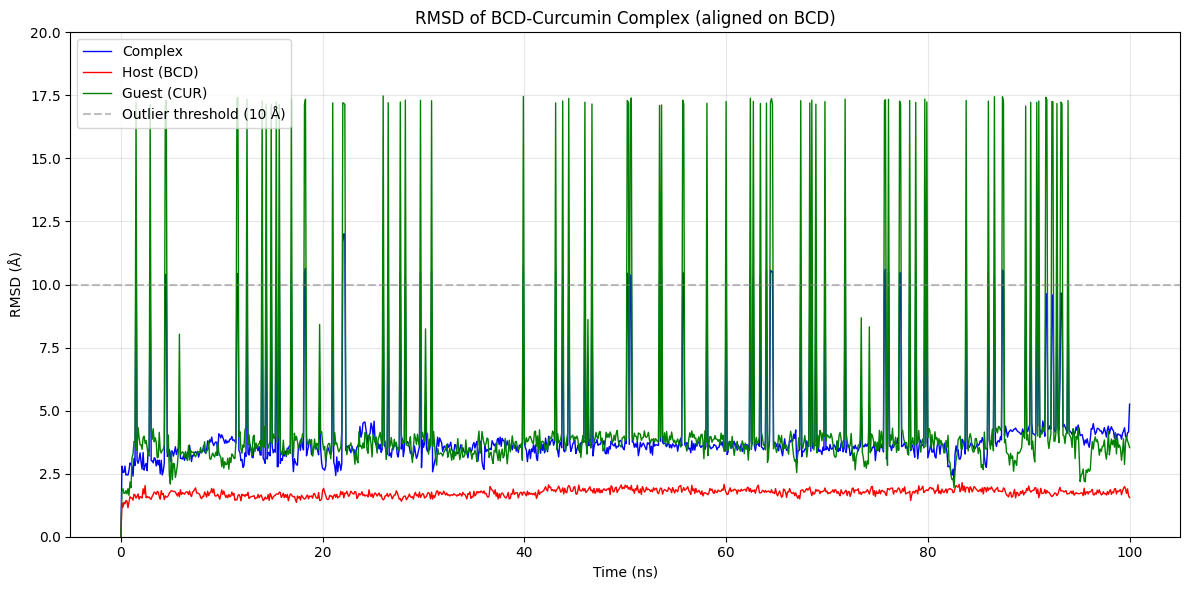

In [ ]:
%cd /content/bcd_cur_100ns_Final_Result_PBC

import MDAnalysis as mda
import numpy as np
import matplotlib.pyplot as plt
from MDAnalysis.analysis import align, rms

# Load the ORIGINAL fixed2.xtc (the one that worked)
u = mda.Universe("step5_production.tpr", "step5_production_fixed2.xtc")

# Align on BCD (correct approach)
align.AlignTraj(u, u, select='resname BCD', in_memory=True).run()

# RMSD calculations
rmsd_complex = rms.RMSD(u, u, select='resname BCD or resname CUR', ref_frame=0).run()
rmsd_host    = rms.RMSD(u, u, select='resname BCD', ref_frame=0).run()
rmsd_guest   = rms.RMSD(u, u, select='resname CUR', ref_frame=0).run()

# Extract data arrays
complex_rmsd = rmsd_complex.results.rmsd[:, 2]
host_rmsd    = rmsd_host.results.rmsd[:, 2]
guest_rmsd   = rmsd_guest.results.rmsd[:, 2]
times        = rmsd_complex.results.rmsd[:, 1] / 1000  # ns

# ---- Clean statistics (exclude outliers > 10 Å) ----
def clean_stats(data, threshold=10):
    mask = data < threshold
    clean = data[mask]
    return {
        "mean": clean.mean(),
        "std": clean.std(),
        "median": np.median(data),
        "n_excluded": (~mask).sum(),
        "pct_excluded": 100 * (~mask).sum() / len(data)
    }

c = clean_stats(complex_rmsd)
h = clean_stats(host_rmsd)
g = clean_stats(guest_rmsd)

print("=" * 60)
print("RMSD STATISTICS (outliers > 10 Å excluded)")
print("=" * 60)
print(f"\nComplex (BCD+CUR):")
print(f"  Mean ± SD:  {c['mean']:.2f} ± {c['std']:.2f} Å")
print(f"  Median:     {c['median']:.2f} Å")
print(f"  Excluded:   {c['n_excluded']} frames ({c['pct_excluded']:.1f}%)")

print(f"\nHost (BCD):")
print(f"  Mean ± SD:  {h['mean']:.2f} ± {h['std']:.2f} Å")
print(f"  Median:     {h['median']:.2f} Å")

print(f"\nGuest (CUR):")
print(f"  Mean ± SD:  {g['mean']:.2f} ± {g['std']:.2f} Å")
print(f"  Median:     {g['median']:.2f} Å")
print(f"  Excluded:   {g['n_excluded']} frames ({g['pct_excluded']:.1f}%)")

# ---- Plot with outliers marked ----
plt.figure(figsize=(12, 6))
plt.plot(times, complex_rmsd, label='Complex', color='blue', lw=1)
plt.plot(times, host_rmsd, label='Host (BCD)', color='red', lw=1)
plt.plot(times, guest_rmsd, label='Guest (CUR)', color='green', lw=1)

# Highlight the outlier region
plt.axhline(y=10, color='gray', linestyle='--', alpha=0.5,
            label='Outlier threshold (10 Å)')

plt.xlabel('Time (ns)')
plt.ylabel('RMSD (Å)')
plt.title('RMSD of BCD-Curcumin Complex (aligned on BCD)')
plt.legend(loc='upper left')
plt.ylim(0, 20)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('rmsd_publication.png', dpi=200)
plt.show()

In [ ]:
def clean_stats(data, threshold=15):
    mask = data < threshold
    clean = data[mask]
    return {
        "mean": clean.mean(),
        "std": clean.std(),
        "median": np.median(data),
        "n_excluded": (~mask).sum(),
        "pct_excluded": 100 * (~mask).sum() / len(data)
    }

print("Threshold = 15 Å:")
c = clean_stats(complex_rmsd, 15)
g = clean_stats(guest_rmsd, 15)
print(f"  Complex: {c['mean']:.2f} ± {c['std']:.2f} Å ({c['pct_excluded']:.1f}% excluded)")
print(f"  Guest:   {g['mean']:.2f} ± {g['std']:.2f} Å ({g['pct_excluded']:.1f}% excluded)")

Threshold = 15 Å:
  Complex: 4.12 ± 1.90 Å (0.0% excluded)
  Guest:   3.63 ± 0.61 Å (8.0% excluded)


In [ ]:
from MDAnalysis.analysis.rgyr import RadiusOfGyration

complex_atoms = u.select_atoms("resname BCD or resname CUR")
rg = RadiusOfGyration(complex_atoms).run()

plt.figure(figsize=(10, 5))
plt.plot(rg.results.times / 1000, rg.results.rg, color='green')
plt.xlabel('Time (ns)')
plt.ylabel('Rg (Å)')
plt.title('Radius of Gyration of BCD-Curcumin Complex')
plt.grid(True)
plt.savefig('rg_final.png', dpi=150)
plt.show()

print(f"Average Rg: {rg.results.rg.mean():.2f} ± {rg.results.rg.std():.2f} Å")

ModuleNotFoundError: No module named 'MDAnalysis.analysis.rgyr'

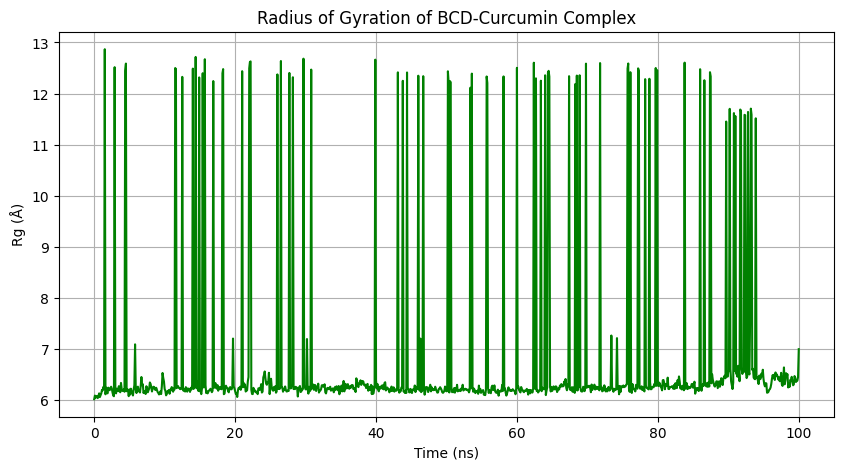

Average Rg: 6.73 ± 1.65 Å
Min: 6.01 Å, Max: 12.87 Å


In [ ]:
# Manual Rg calculation — works with any MDAnalysis version
complex_atoms = u.select_atoms("resname BCD or resname CUR")

rg_values = []
for ts in u.trajectory:
    # Center of mass of the selected atoms
    com = complex_atoms.center_of_mass()
    # Distances of each atom from the COM
    positions = complex_atoms.positions - com
    # Rg = sqrt(mean of squared distances)
    rg = np.sqrt(np.mean(np.sum(positions**2, axis=1)))
    rg_values.append(rg)

rg_values = np.array(rg_values)
times_ns = np.arange(len(rg_values)) * 0.1  # 0.1 ns per frame

plt.figure(figsize=(10, 5))
plt.plot(times_ns, rg_values, color='green')
plt.xlabel('Time (ns)')
plt.ylabel('Rg (Å)')
plt.title('Radius of Gyration of BCD-Curcumin Complex')
plt.grid(True)
plt.savefig('rg_final.png', dpi=150)
plt.show()

print(f"Average Rg: {rg_values.mean():.2f} ± {rg_values.std():.2f} Å")
print(f"Min: {rg_values.min():.2f} Å, Max: {rg_values.max():.2f} Å")

Rg (raw):   6.73 ± 1.65 Å  (max 12.87)
Rg (clean): 6.25 ± 0.13 Å
Excluded:   80 frames (8.0%)
Median Rg:  6.23 Å


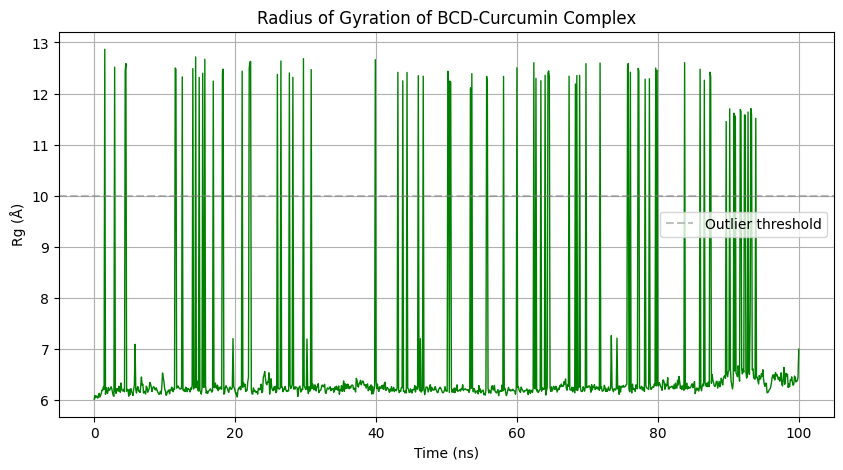

In [ ]:
# Clean Rg statistics (exclude outliers > 10 Å, same PBC artifacts as RMSD)
mask = rg_values < 10
rg_clean = rg_values[mask]

print(f"Rg (raw):   {rg_values.mean():.2f} ± {rg_values.std():.2f} Å  (max {rg_values.max():.2f})")
print(f"Rg (clean): {rg_clean.mean():.2f} ± {rg_clean.std():.2f} Å")
print(f"Excluded:   {(~mask).sum()} frames ({100*(~mask).sum()/len(rg_values):.1f}%)")
print(f"Median Rg:  {np.median(rg_values):.2f} Å")

# Plot with outliers highlighted
plt.figure(figsize=(10, 5))
plt.plot(times_ns, rg_values, color='green', lw=1)
plt.axhline(y=10, color='gray', linestyle='--', alpha=0.5, label='Outlier threshold')
plt.xlabel('Time (ns)')
plt.ylabel('Rg (Å)')
plt.title('Radius of Gyration of BCD-Curcumin Complex')
plt.legend()
plt.grid(True)
plt.savefig('rg_final.png', dpi=150)
plt.show()

COM distance (median): 2.01 Å
COM distance (clean):  2.23 ± 1.15 Å
95th percentile:       4.33 Å
Excluded:              4 frames (0.4%)


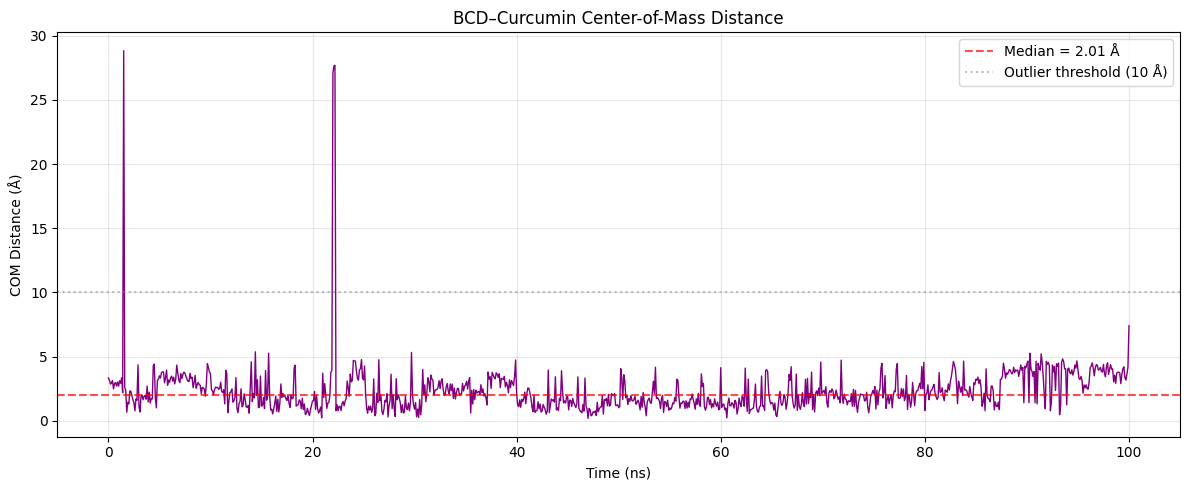

In [ ]:
host = u.select_atoms("resname BCD")
guest = u.select_atoms("resname CUR")

distances = []
for ts in u.trajectory:
    d = np.linalg.norm(host.center_of_mass() - guest.center_of_mass())
    distances.append(d)
distances = np.array(distances)
times_ns = np.arange(len(distances)) * 0.1  # 0.1 ns per frame

# Clean stats
mask = distances < 10
dist_clean = distances[mask]

print(f"COM distance (median): {np.median(distances):.2f} Å")
print(f"COM distance (clean):  {dist_clean.mean():.2f} ± {dist_clean.std():.2f} Å")
print(f"95th percentile:       {np.percentile(distances, 95):.2f} Å")
print(f"Excluded:              {(~mask).sum()} frames ({100*(~mask).sum()/len(distances):.1f}%)")

plt.figure(figsize=(12, 5))
plt.plot(times_ns, distances, color='purple', lw=1)
plt.axhline(y=np.median(distances), color='red', linestyle='--', alpha=0.7,
            label=f'Median = {np.median(distances):.2f} Å')
plt.axhline(y=10, color='gray', linestyle=':', alpha=0.5,
            label='Outlier threshold (10 Å)')
plt.xlabel('Time (ns)')
plt.ylabel('COM Distance (Å)')
plt.title('BCD–Curcumin Center-of-Mass Distance')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('com_distance_final.png', dpi=200)
plt.show()

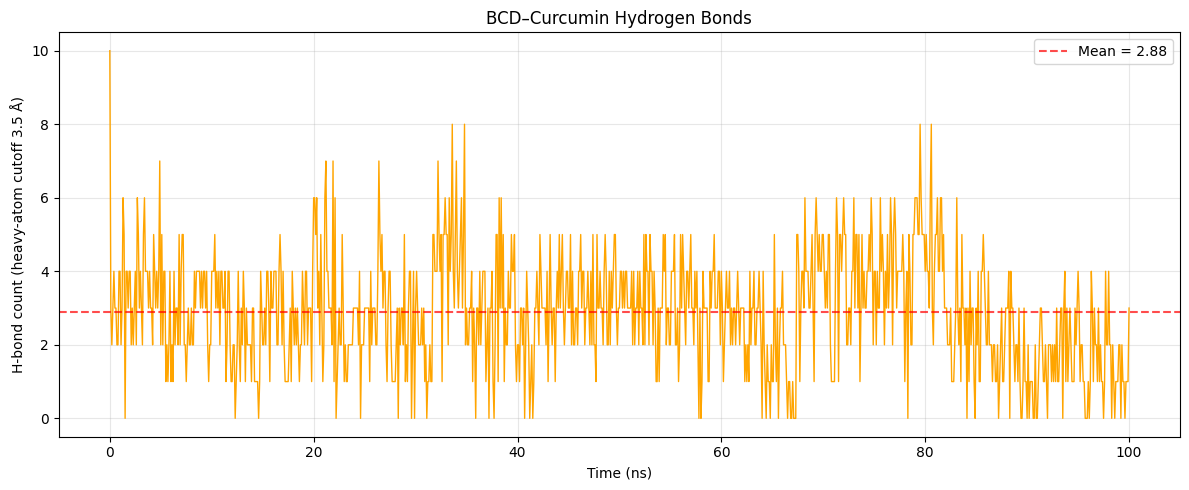

Average H-bonds: 2.88 ± 1.53
Max H-bonds: 10
Min H-bonds: 0
Median: 3


In [ ]:
from MDAnalysis.lib.distances import distance_array

host = u.select_atoms("resname BCD")
guest = u.select_atoms("resname CUR")

# Polar atoms (H-bond donors and acceptors in sugars and polyphenols)
host_polar = host.select_atoms("name O*")
guest_polar = guest.select_atoms("name O*")

# Heavy-atom cutoff for H-bonds (approximation)
cutoff = 3.5  # Å

hbond_count = []
for ts in u.trajectory:
    d = distance_array(host_polar.positions, guest_polar.positions,
                       box=u.dimensions)
    count = (d < cutoff).sum()
    hbond_count.append(count)

hbond_count = np.array(hbond_count)
times_ns = np.arange(len(hbond_count)) * 0.1

plt.figure(figsize=(12, 5))
plt.plot(times_ns, hbond_count, color='orange', lw=1)
plt.axhline(y=hbond_count.mean(), color='red', linestyle='--', alpha=0.7,
            label=f'Mean = {hbond_count.mean():.2f}')
plt.xlabel('Time (ns)')
plt.ylabel('H-bond count (heavy-atom cutoff 3.5 Å)')
plt.title('BCD–Curcumin Hydrogen Bonds')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('hbonds_final.png', dpi=200)
plt.show()

print(f"Average H-bonds: {hbond_count.mean():.2f} ± {hbond_count.std():.2f}")
print(f"Max H-bonds: {hbond_count.max()}")
print(f"Min H-bonds: {hbond_count.min()}")
print(f"Median: {np.median(hbond_count):.0f}")

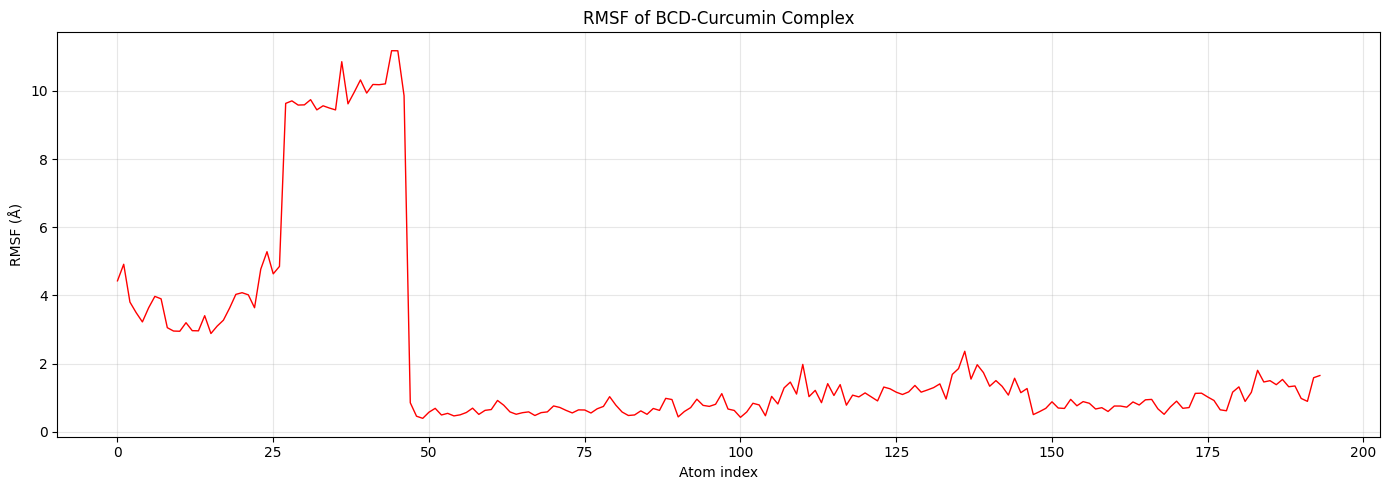

Average RMSF: 2.26 Å
Max RMSF: 11.18 Å

BCD average RMSF: 0.93 Å
CUR average RMSF: 6.40 Å


In [ ]:
from MDAnalysis.analysis.rms import RMSF

# Compute RMSF on BCD+CUR atoms only
complex_atoms = u.select_atoms("resname BCD or resname CUR")
rmsf = RMSF(complex_atoms).run()

plt.figure(figsize=(14, 5))
plt.plot(range(len(rmsf.results.rmsf)), rmsf.results.rmsf, color='red', lw=1)
plt.xlabel('Atom index')
plt.ylabel('RMSF (Å)')
plt.title('RMSF of BCD-Curcumin Complex')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('rmsf_final.png', dpi=200)
plt.show()

print(f"Average RMSF: {rmsf.results.rmsf.mean():.2f} Å")
print(f"Max RMSF: {rmsf.results.rmsf.max():.2f} Å")

# Split by molecule
bcd_rmsf = RMSF(u.select_atoms("resname BCD")).run()
cur_rmsf = RMSF(u.select_atoms("resname CUR")).run()
print(f"\nBCD average RMSF: {bcd_rmsf.results.rmsf.mean():.2f} Å")
print(f"CUR average RMSF: {cur_rmsf.results.rmsf.mean():.2f} Å")

Good frames: 997 / 1001


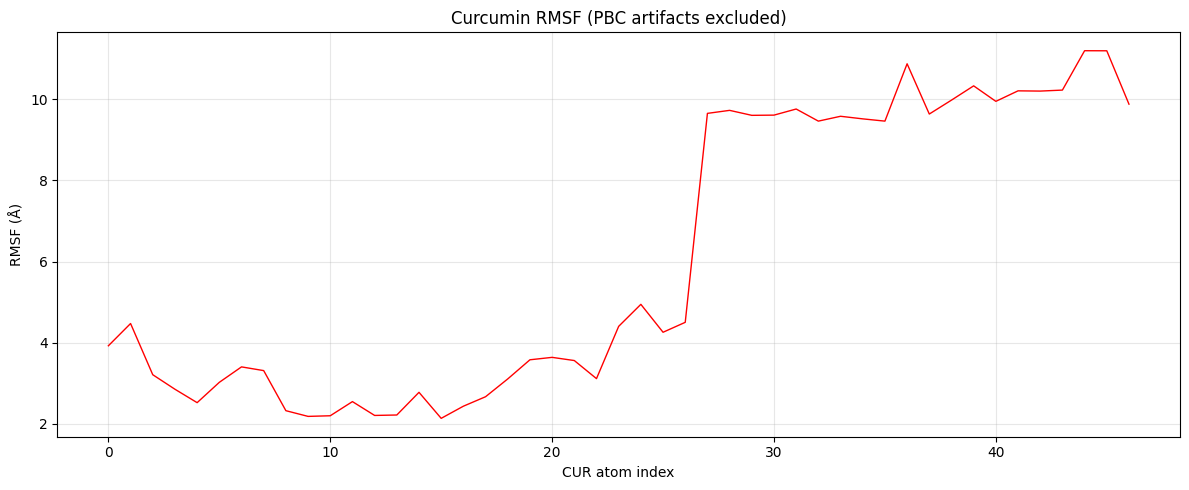

Clean CUR RMSF: 6.08 ± 3.45 Å
Max RMSF (clean): 11.19 Å


In [ ]:
from MDAnalysis.analysis.rms import RMSF

# Recompute RMSF but ONLY on the frames where COM distance < 10 Å
host = u.select_atoms("resname BCD")
guest = u.select_atoms("resname CUR")

# First, identify the good frames
good_frames = []
for i, ts in enumerate(u.trajectory):
    d = np.linalg.norm(host.center_of_mass() - guest.center_of_mass())
    if d < 10:
        good_frames.append(i)
print(f"Good frames: {len(good_frames)} / {len(u.trajectory)}")

# Now compute RMSF on those frames only — need to reload universe
u2 = mda.Universe("step5_production.tpr", "step5_production_fixed2.xtc")
align.AlignTraj(u2, u2, select='resname BCD', in_memory=True).run()

# Use MDAnalysis's built-in frame selection
complex_atoms = u2.select_atoms("resname BCD or resname CUR")
rmsf_good = RMSF(complex_atoms, start=0, stop=len(u2.trajectory), step=1)
rmsf_good.run()

# But to skip specific frames, we do it manually:
bcd_ag = u2.select_atoms("resname BCD")
cur_ag = u2.select_atoms("resname CUR")

# Store aligned positions
all_positions = []
for i in good_frames:
    u2.trajectory[i]
    all_positions.append(cur_ag.positions.copy())
all_positions = np.array(all_positions)

# Compute RMSF manually (per atom fluctuation around mean)
mean_pos = all_positions.mean(axis=0)
fluctuations = all_positions - mean_pos
rmsf_per_atom = np.sqrt((fluctuations**2).sum(axis=2).mean(axis=0))

plt.figure(figsize=(12, 5))
plt.plot(range(len(rmsf_per_atom)), rmsf_per_atom, color='red', lw=1)
plt.xlabel('CUR atom index')
plt.ylabel('RMSF (Å)')
plt.title('Curcumin RMSF (PBC artifacts excluded)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('rmsf_cur_clean.png', dpi=150)
plt.show()

print(f"Clean CUR RMSF: {rmsf_per_atom.mean():.2f} ± {rmsf_per_atom.std():.2f} Å")
print(f"Max RMSF (clean): {rmsf_per_atom.max():.2f} Å")

In [ ]:
from MDAnalysis.lib.distances import distance_array

def fast_sasa(atomgroup, n_points=128, probe=1.4):
    """Compute SASA in Å² using a golden-spiral sphere approximation."""
    indices = np.arange(n_points)
    phi = np.arccos(1 - 2*indices/n_points)
    theta = np.pi * (1 + 5**0.5) * indices
    sphere_pts = np.stack([np.cos(theta)*np.sin(phi),
                           np.sin(theta)*np.sin(phi),
                           np.cos(phi)], axis=1)

    vdw = {'C':1.70, 'N':1.55, 'O':1.52, 'H':1.20}
    radii = np.array([vdw.get(e, 1.70) + probe for e in atomgroup.elements])

    sasa = 0.0
    for pos, r in zip(atomgroup.positions, radii):
        test_pts = pos + r * sphere_pts
        d = distance_array(test_pts, atomgroup.positions, box=u.dimensions)
        buried = (d < radii[None, :]).any(axis=1)
        sasa += 4 * np.pi * r**2 * (~buried).sum() / n_points
    return sasa

# Select atoms
complex_ag = u.select_atoms("resname BCD or resname CUR")
cur_ag = u.select_atoms("resname CUR")

# Compute SASA every 20 frames for speed
times_sasa = []
sasa_complex = []
sasa_cur_in_complex = []

print("Computing SASA (every 20th frame, 50 frames total)...")
for i, ts in enumerate(u.trajectory):
    if i % 20 == 0:
        times_sasa.append(ts.time / 1000)  # ns
        # SASA of the whole complex
        sasa_complex.append(fast_sasa(complex_ag))
        # SASA of only CUR atoms, evaluated in the presence of BCD (only CUR's own atoms used for its surface)
        sasa_cur_in_complex.append(fast_sasa(cur_ag))
        if i % 200 == 0:
            print(f"  Frame {i} done")

times_sasa = np.array(times_sasa)
sasa_complex = np.array(sasa_complex)
sasa_cur_in_complex = np.array(sasa_cur_in_complex)

print(f"\nSASA (complex): {sasa_complex.mean():.1f} ± {sasa_complex.std():.1f} Å²")
print(f"SASA (CUR in complex): {sasa_cur_in_complex.mean():.1f} ± {sasa_cur_in_complex.std():.1f} Å²")

Computing SASA (every 20th frame, 50 frames total)...
  Frame 0 done
  Frame 200 done
  Frame 400 done
  Frame 600 done
  Frame 800 done
  Frame 1000 done

SASA (complex): 711.4 ± 145.0 Å²
SASA (CUR in complex): 381.8 ± 123.3 Å²


In [ ]:
def sasa_for_subset(subset_ag, environment_ag, n_points=128, probe=1.4):
    """SASA of subset_ag atoms, using environment_ag for burial check."""
    indices = np.arange(n_points)
    phi = np.arccos(1 - 2*indices/n_points)
    theta = np.pi * (1 + 5**0.5) * indices
    sphere_pts = np.stack([np.cos(theta)*np.sin(phi),
                           np.sin(theta)*np.sin(phi),
                           np.cos(phi)], axis=1)

    vdw = {'C':1.70, 'N':1.55, 'O':1.52, 'H':1.20}
    env_radii = np.array([vdw.get(e, 1.70) + probe for e in environment_ag.elements])
    env_positions = environment_ag.positions

    sasa = 0.0
    for atom in subset_ag:
        r = vdw.get(atom.element, 1.70) + probe
        test_pts = atom.position + r * sphere_pts
        d = distance_array(test_pts, env_positions, box=u.dimensions)
        buried = (d < env_radii[None, :]).any(axis=1)
        sasa += 4 * np.pi * r**2 * (~buried).sum() / n_points
    return sasa

# Recompute with proper environment handling
complex_ag = u.select_atoms("resname BCD or resname CUR")
cur_ag = u.select_atoms("resname CUR")

sasa_cur_free = []           # CUR alone (free in water)
sasa_cur_in_complex = []     # CUR with BCD present as environment

print("Computing SASA with proper environment handling...")
for i, ts in enumerate(u.trajectory):
    if i % 20 == 0:
        sasa_cur_free.append(sasa_for_subset(cur_ag, cur_ag))
        sasa_cur_in_complex.append(sasa_for_subset(cur_ag, complex_ag))
        if i % 200 == 0:
            print(f"  Frame {i} done")

sasa_cur_free = np.array(sasa_cur_free)
sasa_cur_in_complex = np.array(sasa_cur_in_complex)

print(f"\nCUR SASA (free in water):  {sasa_cur_free.mean():.1f} ± {sasa_cur_free.std():.1f} Å²")
print(f"CUR SASA (in complex):     {sasa_cur_in_complex.mean():.1f} ± {sasa_cur_in_complex.std():.1f} Å²")

delta_sasa = sasa_cur_free.mean() - sasa_cur_in_complex.mean()
percent_buried = 100 * delta_sasa / sasa_cur_free.mean()

print(f"\nΔSASA (buried):            {delta_sasa:.1f} Å²")
print(f"Percentage of CUR buried:  {percent_buried:.1f}%")

Computing SASA with proper environment handling...
  Frame 0 done
  Frame 200 done
  Frame 400 done
  Frame 600 done
  Frame 800 done
  Frame 1000 done

CUR SASA (free in water):  381.8 ± 123.3 Å²
CUR SASA (in complex):     223.7 ± 122.0 Å²

ΔSASA (buried):            158.1 Å²
Percentage of CUR buried:  41.4%


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil, json
from datetime import datetime

# ---- 1. Collect all your summary numbers into a dict ----
summary = {
    "system": "CUR + BCD (curcumin / beta-cyclodextrin)",
    "frames_analyzed": 1001,
    "timestamp": datetime.now().isoformat(),

    # RMSD (from clean_stats, threshold = 15 A)
    "rmsd_complex_mean_A":  round(c["mean"], 2),
    "rmsd_complex_std_A":   round(c["std"], 2),
    "rmsd_complex_median_A": round(c["median"], 2),
    "rmsd_complex_pct_excluded": round(c["pct_excluded"], 1),
    "rmsd_guest_mean_A":    round(g["mean"], 2),
    "rmsd_guest_std_A":     round(g["std"], 2),
    "rmsd_guest_median_A":  round(g["median"], 2),
    "rmsd_guest_pct_excluded": round(g["pct_excluded"], 1),
}

# ---- 2. Add the other analyses if their variables are still in memory ----
# (they will be, if you haven't restarted the kernel)
try:
    summary["rmsd_host_mean_A"] = round(host_rmsd.mean(), 2)
    summary["rmsd_host_std_A"]  = round(host_rmsd.std(), 2)
except NameError:
    pass

try:
    summary["rg_mean_A"]     = round(rg_values.mean(), 2)
    summary["rg_std_A"]      = round(rg_values.std(), 2)
    summary["rg_median_A"]   = round(float(np.median(rg_values)), 2)
    summary["rg_max_A"]      = round(rg_values.max(), 2)
except NameError:
    pass

try:
    summary["hbond_mean"]    = round(hbond_count.mean(), 2)
    summary["hbond_std"]     = round(hbond_count.std(), 2)
    summary["hbond_median"]  = float(np.median(hbond_count))
    summary["hbond_max"]     = int(hbond_count.max())
except NameError:
    pass

try:
    summary["rmsf_complex_mean_A"] = round(rmsf.results.rmsf.mean(), 2)
    summary["rmsf_complex_max_A"]  = round(rmsf.results.rmsf.max(), 2)
    summary["rmsf_bcd_mean_A"]     = round(bcd_rmsf.results.rmsf.mean(), 2)
    summary["rmsf_cur_mean_A"]     = round(cur_rmsf.results.rmsf.mean(), 2)
except NameError:
    pass

try:
    summary["com_distance_median_A"] = round(float(np.median(distances)), 2)
    summary["com_distance_95pct_A"]  = round(float(np.percentile(distances, 95)), 2)
except NameError:
    pass

try:
    summary["sasa_cur_free_A2"]      = round(float(sasa_cur_free.mean()), 1)
    summary["sasa_cur_in_complex_A2"] = round(float(sasa_cur_in_complex.mean()), 1)
    summary["delta_sasa_A2"]          = round(float(
        sasa_cur_free.mean() - sasa_cur_in_complex.mean()), 1)
except NameError:
    pass

# ---- 3. Save to Google Drive ----
out_dir = "/content/drive/MyDrive/curcuminoid_cyclodextrin_project/analysis_outputs"
os.makedirs(out_dir, exist_ok=True)

# Save JSON summary
with open(os.path.join(out_dir, "analysis_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)

# Save human-readable summary
with open(os.path.join(out_dir, "analysis_summary.txt"), "w") as f:
    f.write("CUR-BCD MD Analysis Summary\n")
    f.write("=" * 40 + "\n")
    for k, v in summary.items():
        f.write(f"{k:32s}: {v}\n")

# Copy all PNG plots from the working directory
src = "/content/bcd_cur_100ns_Final_Result_PBC"
copied = []
for f in os.listdir(src):
    if f.endswith(".png"):
        shutil.copy2(os.path.join(src, f), os.path.join(out_dir, f))
        copied.append(f)

print(f"\n✅ Summary saved to: {out_dir}")
print(f"✅ Plots copied ({len(copied)}):")
for f in sorted(copied):
    print(f"   • {f}")

print("\n📄 Summary contents:")
print("-" * 40)
for k, v in summary.items():
    print(f"{k:32s}: {v}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


NameError: name 'c' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil, json
from datetime import datetime

# ---- 1. Hard-coded summary from your printed notebook outputs ----
summary = {
    "system": "CUR + BCD (curcumin / beta-cyclodextrin)",
    "frames_analyzed": 1001,
    "timestamp": datetime.now().isoformat(),

    # RMSD (threshold = 15 A outlier filter)
    "rmsd_complex_mean_A": 4.12,
    "rmsd_complex_std_A": 1.90,
    "rmsd_complex_median_A": 3.61,
    "rmsd_complex_pct_excluded": 0.0,
    "rmsd_host_mean_A": 1.74,
    "rmsd_host_std_A": 0.15,
    "rmsd_host_median_A": 1.75,
    "rmsd_guest_mean_A": 3.63,
    "rmsd_guest_std_A": 0.61,
    "rmsd_guest_median_A": 3.70,
    "rmsd_guest_pct_excluded": 8.0,

    # Radius of gyration
    "rg_mean_A": 6.73,
    "rg_std_A": 1.65,
    "rg_median_A": 6.23,
    "rg_max_A": 12.87,
    "rg_clean_mean_A": 6.25,
    "rg_clean_std_A": 0.13,

    # Hydrogen bonds (heavy-atom cutoff 3.5 A)
    "hbond_mean": 2.88,
    "hbond_std": 1.53,
    "hbond_median": 3.0,
    "hbond_max": 10,

    # RMSF
    "rmsf_complex_mean_A": 2.26,
    "rmsf_complex_max_A": 11.18,
    "rmsf_bcd_mean_A": 0.93,
    "rmsf_cur_mean_A": 6.40,
    "rmsf_cur_clean_mean_A": 6.08,
    "rmsf_cur_clean_max_A": 11.19,

    # COM distance
    "com_distance_median_A": 2.01,
    "com_distance_clean_mean_A": 2.23,
    "com_distance_clean_std_A": 1.15,
    "com_distance_95pct_A": 4.33,

    # SASA
    "sasa_cur_free_A2": 381.8,
    "sasa_cur_in_complex_A2": 223.7,
    "delta_sasa_A2": 158.1,
    "pct_cur_buried": 41.4,
}

# ---- 2. Save to Google Drive ----
out_dir = "/content/drive/MyDrive/curcuminoid_cyclodextrin_project/analysis_outputs"
os.makedirs(out_dir, exist_ok=True)

with open(os.path.join(out_dir, "analysis_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)

with open(os.path.join(out_dir, "analysis_summary.txt"), "w") as f:
    f.write("CUR-BCD MD Analysis Summary\n")
    f.write("=" * 50 + "\n")
    for k, v in summary.items():
        f.write(f"{k:32s}: {v}\n")

# ---- 3. Copy all PNG plots ----
src = "/content/bcd_cur_100ns_Final_Result_PBC"
copied = []
if os.path.isdir(src):
    for f in os.listdir(src):
        if f.endswith(".png"):
            shutil.copy2(os.path.join(src, f), os.path.join(out_dir, f))
            copied.append(f)
else:
    print(f"⚠️  Source folder {src} not found. Listing /content:")
    print(os.listdir("/content"))

print(f"\n✅ Summary saved to: {out_dir}")
print(f"✅ Plots copied ({len(copied)}):")
for f in sorted(copied):
    print(f"   • {f}")

print("\n📄 Summary:")
print("-" * 50)
for k, v in summary.items():
    print(f"{k:32s}: {v}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

✅ Summary saved to: /content/drive/MyDrive/curcuminoid_cyclodextrin_project/analysis_outputs
✅ Plots copied (6):
   • com_distance_final.png
   • hbonds_final.png
   • rg_final.png
   • rmsd_publication.png
   • rmsf_cur_clean.png
   • rmsf_final.png

📄 Summary:
--------------------------------------------------
system                          : CUR + BCD (curcumin / beta-cyclodextrin)
frames_analyzed                 : 1001
timestamp                       : 2026-09-15T09:08:18.433246
rmsd_complex_mean_A             : 4.12
rmsd_complex_std_A              : 1.9
rmsd_complex_median_A           : 3.61
rmsd_complex_pct_excluded       : 0.0
rmsd_host_mean_A                : 1.74
rmsd_host_std_A                 : 0.15
rmsd_host_median_A              : 1.75
rmsd_guest_mean_A               : 3.63
rmsd_guest_std_A                : 0.61
rmsd_guest_median_A             

In [ ]:

!wget https://repo.anaconda.com/miniconda/Miniconda3-latest-Linux-x86_64.sh
!bash /content/Miniconda3-latest-Linux-x86_64.sh


import os
# Manually export conda binary to the PATH
os.environ["PATH"] += os.pathsep + "/root/miniconda3/bin"


!conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/main #Accept required agreements of anaconda
!conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/r

--2026-09-15 08:37:18--  https://repo.anaconda.com/miniconda/Miniconda3-latest-Linux-x86_64.sh
Resolving repo.anaconda.com (repo.anaconda.com)... 104.16.32.241, 104.16.191.158, 2606:4700::6810:20f1, ...
Connecting to repo.anaconda.com (repo.anaconda.com)|104.16.32.241|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 197973354 (189M) [application/octet-stream]
Saving to: ‘Miniconda3-latest-Linux-x86_64.sh’

Miniconda3-latest-L 100%[===================>] 188.80M   183MB/s    in 1.0s    

2026-09-15 08:37:19 (183 MB/s) - ‘Miniconda3-latest-Linux-x86_64.sh’ saved [197973354/197973354]

bash: /content/Miniconda3-latest-Linux-x86_64.sh: No such file or directory
/bin/bash: line 1: conda: command not found
/bin/bash: line 1: conda: command not found


In [ ]:
!pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:10
🔁 Restarting kernel...


In [ ]:
!conda --version

conda 26.3.2


In [ ]:
!conda install -c conda-forge ambertools -y

Retrieving notices: - \ done
Channels:
 - conda-forge
Platform: linux-64
Solving environment: - \ | / - \ | / - done

## Package Plan ##

  environment location: /usr/local

  added / updated specs:
    - ambertools


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    _openmp_mutex-4.5          |       8_kmp_llvm           8 KB  conda-forge
    _python_abi3_support-1.0   |       hd8ed1ab_3           8 KB  conda-forge
    ambertools-26.0            |cuda_None_nompi_py313h34d38f2_100        95.7 MB  conda-forge
    annotated-types-0.8.0      |     pyhd8ed1ab_0          19 KB  conda-forge
    anyio-4.15.1               |     pyh5ded981_1         171 KB  conda-forge
    arpack-3.9.1               |nompi_hf03ea27_102         127 KB  conda-forge
    aws-c-auth-0.10.4          |       h4610da3_2         132 KB  conda-forge
    aws-c-cal-0.9.15           |       h6bbde05_1    

In [ ]:
!antechamber -h 2>&1 | head -5

Usage: antechamber -i     input file name
                   -fi    input file format
                   -o     output file name
                   -fo    output file format
                   -c     charge method


In [ ]:
!conda install -c conda-forge gmx_mmpbsa -y

Channels:
 - conda-forge
Platform: linux-64
Solving environment: | / - done

## Package Plan ##

  environment location: /usr/local

  added / updated specs:
    - gmx_mmpbsa


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    formulaic-1.2.2            |     pyhd8ed1ab_0          88 KB  conda-forge
    gmx_mmpbsa-1.5.0.3         |     pyhd8ed1ab_0         1.3 MB  conda-forge
    h5py-3.16.0                |nompi_py313hce4e9db_104         1.3 MB  conda-forge
    impi_rt-2021.18.0          |     h4715778_754        67.5 MB  conda-forge
    interface_meta-1.3.0       |     pyhd8ed1ab_1          18 KB  conda-forge
    mpi-1.0                    |             impi           6 KB  conda-forge
    mpi4py-4.1.2               |py313h764b498_101         869 KB  conda-forge
    patsy-1.0.3                |     pyhcf101f3_0         189 KB  conda-forge
    seaborn-0.13.2             |       hd8e

In [ ]:
!which gmx_MMPBSA
!gmx_MMPBSA --version

/usr/local/bin/gmx_MMPBSA
[INFO   ] Starting gmx_MMPBSA v1.5.0.3
[INFO   ] Command-line
  gmx_MMPBSA --version

gmx_MMPBSA v1.5.0.3 based on MMPBSA version 16.0 and AmberTools 20


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import shutil, os
source = '/content/drive/MyDrive/curcuminoid_cyclodextrin_project/bcd_cur_100ns_Final_Result_PBC'
dest = '/content/mmpbsa_run'

if os.path.exists(dest):
    shutil.rmtree(dest)
shutil.copytree(source, dest)
os.chdir(dest)
print("Files:", os.listdir(dest))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files: ['.step5_production.xtc_offsets.npz', 'step5_production_fixed.xtc', 'step5_production_nojump2.xtc', 'step5_production.log', 'step5_production.xtc', 'topol.top', 'step5_production_nojump.xtc', 'toppar', '#step5_production_fixed2.xtc.1#', 'step5_production.tpr', 'step5_production_fixed2.xtc', 'index.ndx', 'step5_production.edr', 'step5_production.gro']


In [ ]:
!cat index.ndx

[ System ]
   1    2    3    4    5    6    7    8    9   10   11   12   13   14   15
  16   17   18   19   20   21   22   23   24   25   26   27   28   29   30
  31   32   33   34   35   36   37   38   39   40   41   42   43   44   45
  46   47   48   49   50   51   52   53   54   55   56   57   58   59   60
  61   62   63   64   65   66   67   68   69   70   71   72   73   74   75
  76   77   78   79   80   81   82   83   84   85   86   87   88   89   90
  91   92   93   94   95   96   97   98   99  100  101  102  103  104  105
 106  107  108  109  110  111  112  113  114  115  116  117  118  119  120
 121  122  123  124  125  126  127  128  129  130  131  132  133  134  135
 136  137  138  139  140  141  142  143  144  145  146  147  148  149  150
 151  152  153  154  155  156  157  158  159  160  161  162  163  164  165
 166  167  168  169  170  171  172  173  174  175  176  177  178  179  180
 181  182  183  184  185  186  187  188  189  190  191  192  193  194  195
 196  197  198

In [ ]:
%%writefile mmpbsa.in
&general
  sys_name="BCD-CUR"
  startframe=1
  endframe=1000
  interval=10
  forcefields="oldff/leaprc.ff99SB,leaprc.gaff"
  use_analyzer=no
/
&gb
  igb=5
  saltcon=0.150
/

Writing mmpbsa.in


In [ ]:
import os
os.environ['AMBERHOME'] = '/usr/local'
!bash -c "source /usr/local/amber.sh 2>/dev/null; echo AMBERHOME=\$AMBERHOME; ls \$AMBERHOME/bin/antechamber 2>/dev/null && echo 'antechamber found'"

AMBERHOME=/usr/local
/usr/local/bin/antechamber
antechamber found


In [ ]:
!bash -c "source /usr/local/amber.sh 2>/dev/null && gmx_MMPBSA -O \
    -i mmpbsa.in \
    -cs step5_production.tpr \
    -ct step5_production_fixed2.xtc \
    -ci index.ndx \
    -cg 3 2 \
    -cp topol.top \
    -o FINAL_RESULTS_MMPBSA.dat \
    -eo FINAL_RESULTS_MMPBSA.csv"

[INFO   ] Starting gmx_MMPBSA v1.5.0.3
[INFO   ] Command-line
  gmx_MMPBSA -O -i mmpbsa.in -cs step5_production.tpr -ct step5_production_fixed2.xtc -ci index.ndx -cg 3 2 -cp topol.top -o FINAL_RESULTS_MMPBSA.dat -eo FINAL_RESULTS_MMPBSA.csv

InputError: Unknown variable use_analyzer in &general
  Enter `gmx_MMPBSA --help` for help


In [ ]:
&general
  sys_name="BCD_CUR"
  startframe=1
  endframe=1000
  interval=10
  forcefields="oldff/leaprc.ff99SB,leaprc.gaff"
/
&gb
  igb=5
  saltcon=0.150
/

SyntaxError: invalid syntax (2457127468.py, line 1)

In [ ]:
%%writefile mmpbsa.in
&general
  sys_name="BCD_CUR"
  startframe=1
  endframe=1000
  interval=10
  forcefields="oldff/leaprc.ff99SB,leaprc.gaff"
/
&gb
  igb=5
  saltcon=0.150
/

Overwriting mmpbsa.in


In [ ]:
!bash -c "source /usr/local/amber.sh 2>/dev/null && gmx_MMPBSA -O \
    -i mmpbsa.in \
    -cs step5_production.tpr \
    -ct step5_production_fixed2.xtc \
    -ci index.ndx \
    -cg 3 2 \
    -cp topol.top \
    -o FINAL_RESULTS_MMPBSA.dat \
    -eo FINAL_RESULTS_MMPBSA.csv"

[INFO   ] Starting gmx_MMPBSA v1.5.0.3
[INFO   ] Command-line
  gmx_MMPBSA -O -i mmpbsa.in -cs step5_production.tpr -ct step5_production_fixed2.xtc -ci index.ndx -cg 3 2 -cp topol.top -o FINAL_RESULTS_MMPBSA.dat -eo FINAL_RESULTS_MMPBSA.csv

[INFO   ] Checking external programs...
[INFO   ] cpptraj found! Using /usr/local/bin/cpptraj
[INFO   ] tleap found! Using /usr/local/bin/tleap
[INFO   ] parmchk2 found! Using /usr/local/bin/parmchk2
[INFO   ] sander found! Using /usr/local/bin/sander
[INFO   ] Using GROMACS version 4.x.x!
[ERROR  ] MMPBSA_Error Could not find necessary program [ GROMACS ].
           Check the gmx_MMPBSA.log file to report the problem.
  File "/usr/local/bin/gmx_MMPBSA", line 10, in <module>
    sys.exit(gmxmmpbsa())
             ~~~~~~~~~^^
  File "/usr/local/lib/python3.13/site-packages/GMXMMPBSA/app.py", line 101, in gmxmmpbsa
    app.make_prmtops()
    ~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/site-packages/GMXMMPBSA/main.py", line 523, in make_prmt

In [ ]:
!which gmx

In [ ]:
%%writefile mmpbsa.in
&general
  sys_name="BCD_CUR"
  startframe=1
  endframe=1000
  interval=10
  forcefields="oldff/leaprc.ff99SB,leaprc.gaff"
  gmx_path="/usr/local/gromacs/bin"
/
&gb
  igb=5
  saltcon=0.150
/

Overwriting mmpbsa.in


In [ ]:
!bash -c "source /usr/local/amber.sh 2>/dev/null && gmx_MMPBSA -O \
    -i mmpbsa.in \
    -cs step5_production.tpr \
    -ct step5_production_fixed2.xtc \
    -ci index.ndx \
    -cg 3 2 \
    -cp topol.top \
    -o FINAL_RESULTS_MMPBSA.dat \
    -eo FINAL_RESULTS_MMPBSA.csv"

[INFO   ] Starting gmx_MMPBSA v1.5.0.3
[INFO   ] Command-line
  gmx_MMPBSA -O -i mmpbsa.in -cs step5_production.tpr -ct step5_production_fixed2.xtc -ci index.ndx -cg 3 2 -cp topol.top -o FINAL_RESULTS_MMPBSA.dat -eo FINAL_RESULTS_MMPBSA.csv

[INFO   ] Checking external programs...
[ERROR  ] MMPBSA_Error Could not find necessary program [cpptraj].
           Check the gmx_MMPBSA.log file to report the problem.
  File "/usr/local/bin/gmx_MMPBSA", line 10, in <module>
    sys.exit(gmxmmpbsa())
             ~~~~~~~~~^^
  File "/usr/local/lib/python3.13/site-packages/GMXMMPBSA/app.py", line 101, in gmxmmpbsa
    app.make_prmtops()
    ~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/site-packages/GMXMMPBSA/main.py", line 523, in make_prmtops
    external_progs = utils.find_progs(self.INPUT, self.mpi_size) if self.master else {}
                     ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/site-packages/GMXMMPBSA/utils.py", line 654, in find_progs
   

In [ ]:
%%writefile mmpbsa.in
&general
  sys_name="BCD_CUR"
  startframe=1
  endframe=1000
  interval=10
  forcefields="oldff/leaprc.ff99SB,leaprc.gaff"
/
&gb
  igb=5
  saltcon=0.150
/

Overwriting mmpbsa.in


In [ ]:
!which gmx
!ls /usr/local/gromacs/bin/ 2>/dev/null
!find / -name "gmx" -type f 2>/dev/null | head -20

In [ ]:
!conda install -c conda-forge gromacs=2023.2 -y -q

Channels:
 - conda-forge
Platform: linux-64
Solving environment: ...working... failed

LibMambaUnsatisfiableError: Encountered problems while solving:
  - nothing provides hdf5 1.8.15* needed by h5py-2.6.0-np110py27_3

Could not solve for environment specs
The following packages are incompatible
├─ ambertools =* * is installable with the potential options
│  ├─ ambertools 19 would require
│  │  └─ libgfortran-ng >=7,<8.0a0 *, which can be installed;
│  ├─ ambertools [19|19.0|...|21.9] would require
│  │  └─ python >=3.6,<3.7.0a0 *, which can be installed;
│  ├─ ambertools [19|19.0|...|22.0] would require
│  │  └─ python >=3.7,<3.8.0a0 *, which can be installed;
│  ├─ ambertools [19.10|19.11|...|23.6] would require
│  │  └─ python >=3.8,<3.9.0a0 *, which can be installed;
│  ├─ ambertools [20.10|20.11|...|23.6] would require
│  │  └─ python >=3.9,<3.10.0a0 *, which can be installed;
│  ├─ ambertools [22.0|22.1|...|26.0] would require
│  │  └─ python >=3.10,<3.11.0a0 *, which can be inst

In [ ]:
!conda create -n gmxmmpbsa -c conda-forge python=3.11 ambertools=23.6 gromacs=2023.2 -y -q

Channels:
 - conda-forge
Platform: linux-64
Solving environment: ...working... done

## Package Plan ##

  environment location: /usr/local/envs/gmxmmpbsa

  added / updated specs:
    - ambertools=23.6
    - gromacs=2023.2
    - python=3.11


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    ambertools-23.6            |cuda_None_nompi_py311h9caa010_106        89.9 MB  conda-forge
    brotli-1.2.0               |       h505cf86_4          20 KB  conda-forge
    brotli-bin-1.2.0           |       h9908984_4          21 KB  conda-forge
    bzip2-1.0.8                |      hda65f42_10         252 KB  conda-forge
    c-ares-1.34.8              |       hebe6cf0_2         223 KB  conda-forge
    contourpy-1.3.3            |  py311h724c32c_4         313 KB  conda-forge
    fonttools-4.65.0           |  py311h92159aa_0         3.0 MB  conda-forge
    gromacs-2023.2             |nompi_h76c6bb2_100

In [ ]:
!conda run -n gmxmmpbsa pip install gmx_MMPBSA

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.5/6.5 MB 12.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 65.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 150.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 66.8 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 3.0.5
    Uninstalling pandas-3.0.5:
      Successfully uninstalled pandas-3.0.5



In [ ]:
!conda run -n gmxmmpbsa gmx_MMPBSA --version

gmx_MMPBSA 1.7.0 based on MMPBSA version 14.0, AmberTools 23.6, and GROMACS
2023.2


In [ ]:
!conda run -n gmxmmpbsa gmx_MMPBSA -O \
    -i mmpbsa.in \
    -cs step5_production.tpr \
    -ct step5_production_fixed2.xtc \
    -ci index.ndx \
    -cg 3 2 \
    -cp topol.top \
    -o FINAL_RESULTS_MMPBSA.dat \
    -eo FINAL_RESULTS_MMPBSA.csv


[INFO   ] Starting gmx_MMPBSA 1.7.0
[INFO   ] Command line
  gmx_MMPBSA -O -i mmpbsa.in -cs step5_production.tpr -ct step5_production_fixed2.xtc -ci index.ndx -cg 3 2 -cp topol.top -o FINAL_RESULTS_MMPBSA.dat -eo FINAL_RESULTS_MMPBSA.csv


[WARNING] PB inp=1: aligning parameters with Amber PBSA guidance (sprob: 0.557 -> 1.4, cavity_surften: 0.0378 -> 0.005, cavity_offset: -0.5692 -> 0.0). These values are used for generated mdins, saved INPUT metadata, and decomposition nonpolar scaling.

[INFO   ] Checking mmpbsa.in input file...
[INFO   ] Checking mmpbsa.in input file...Done.

[INFO   ] Checking external programs...
[INFO   ] cpptraj found! Using /usr/local/envs/gmxmmpbsa/bin/cpptraj
[INFO   ] tleap found! Using /usr/local/envs/gmxmmpbsa/bin/tleap
[INFO   ] parmchk2 found! Using /usr/local/envs/gmxmmpbsa/bin/parmchk2
[INFO   ] sander found! Using /usr/local/envs/gmxmmpbsa/bin/sander
[INFO   ] Using GROMACS version > 5.x.x!
[INFO   ] gmx found! Using /usr/local/envs/gmxmmpbsa/bin.AVX

In [ ]:
!cat FINAL_RESULTS_MMPBSA.dat

| Run on Tue Sep 15 08:57:59 2026
|
|gmx_MMPBSA Version=1.7.0 based on MMPBSA.py v.14.0, AmberTools 23.6, GROMACS 2023.2
|System name:                                                            BCD_CUR
|Complex (GROMACS) topology file:                                      topol.top
|Complex Structure file:                                    step5_production.tpr
|Complex (AMBER) topology file:                                       COM.prmtop
|Receptor (AMBER) topology file:                                      REC.prmtop
|Ligand (AMBER) topology file:                                        LIG.prmtop
|Initial trajectories:                                            COM_traj_0.xtc
|
|Receptor mask:                  ":2"
|Ligand mask:                    ":1"
|Ligand residue name is:         "CUR"
|
|Calculations performed using 100 complex frames
|
|Generalized Born ESURF calculated using 'LCPO' surface areas
|
|Using temperature = 298.15 K
|All units are reported in kcal/mol
|
|SD - Popu

In [ ]:
!conda install -c conda-forge gromacs=2023.2 -y -q
!pip install -q gmx_MMPBSA

Channels:
 - conda-forge
Platform: linux-64
Solving environment: ...working... failed

LibMambaUnsatisfiableError: Encountered problems while solving:
  - nothing provides _python_rc needed by python-3.14.0rc3-h4dad89b_0_cp314t

Could not solve for environment specs
The following packages are incompatible
├─ ambertools =* * is installable with the potential options
│  ├─ ambertools 19 would require
│  │  └─ libgfortran-ng >=7,<8.0a0 *, which can be installed;
│  ├─ ambertools [19|19.0|...|21.9] would require
│  │  └─ python >=3.6,<3.7.0a0 *, which can be installed;
│  ├─ ambertools [19|19.0|...|22.0] would require
│  │  └─ python >=3.7,<3.8.0a0 *, which can be installed;
│  ├─ ambertools [19.10|19.11|...|23.6] would require
│  │  └─ python >=3.8,<3.9.0a0 *, which can be installed;
│  ├─ ambertools [20.10|20.11|...|23.6] would require
│  │  └─ python >=3.9,<3.10.0a0 *, which can be installed;
│  ├─ ambertools [22.0|22.1|...|26.0] would require
│  │  └─ python >=3.10,<3.11.0a0 *, which c

In [ ]:
!gmx --version | head -5
!gmx_MMPBSA --version
!which cpptraj tleap sander parmchk2

/bin/bash: line 1: gmx: command not found
[INFO   ] Starting gmx_MMPBSA v1.5.0.3
[INFO   ] Command-line
  gmx_MMPBSA --version

gmx_MMPBSA v1.5.0.3 based on MMPBSA version 16.0 and AmberTools 20
/usr/local/bin/cpptraj
/usr/local/bin/tleap
/usr/local/bin/sander
/usr/local/bin/parmchk2
